# Modelisation

Comparaison initiale sur 1280 lignes d apprentissage et 320 de validation. Le test reste a part. Projet pedagogique, sans usage clinique.

## 1. Imports

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.train import train_model
from src.evaluate import evaluate_model


## 2. Donnees

Reprendre le split 80/20, puis creer la validation dans le train.

In [2]:
df = pd.read_csv(PROJECT_ROOT / "data/raw/student_mental_health.csv")
df = df.drop_duplicates().dropna(subset=["Mental_Health_Risk"]).copy()
X = df.drop(columns=["Student_ID", "Mental_Health_Risk"])
y = df["Mental_Health_Risk"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Train disponible :", X_train.shape)
print("Test final reserve :", X_test.shape)


Train disponible : (1600, 15)
Test final reserve : (400, 15)


In [3]:
X_fit, X_validation, y_fit_text, y_validation_text = train_test_split(
    X_train, y_train, test_size=0.20, random_state=42, stratify=y_train
)
print("Apprentissage :", X_fit.shape)
print("Validation :", X_validation.shape)

assert set(X_fit.index).isdisjoint(X_validation.index)
assert set(X_train.index).isdisjoint(X_test.index)


Apprentissage : (1280, 15)
Validation : (320, 15)


In [4]:
label_encoder = LabelEncoder()
y_fit = label_encoder.fit_transform(y_fit_text)
y_validation = label_encoder.transform(y_validation_text)
class_names = label_encoder.classes_

display(pd.DataFrame({"Code": range(len(class_names)), "Classe": class_names}))


,Code,Classe
0,0,High
1,1,Low
2,2,Medium


## 3. Modeles

Les trois modeles utilisent le meme preprocessing.

In [5]:
models = {
    "Logistic Regression": LogisticRegression(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "XGBoost": XGBClassifier(
        n_estimators=200, max_depth=3, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8,
        objective="multi:softprob", eval_metric="mlogloss",
        tree_method="hist", random_state=42, n_jobs=2,
    ),
}


## 4. Entrainement et evaluation

Apprendre sur X_fit et comparer les scores sur X_validation.

In [6]:
trained_models = {}
evaluations = {}
comparison_rows = []

for name, model in models.items():
    print("Entrainement :", name)

    trained_pipeline = train_model(model, X_fit, y_fit, use_outliers=True)
    trained_models[name] = trained_pipeline

    result = evaluate_model(trained_pipeline, X_validation, y_validation, class_names)
    evaluations[name] = result

    row = {"Modele": name}
    row.update(result["metrics"])
    comparison_rows.append(row)

comparison = pd.DataFrame(comparison_rows).set_index("Modele")
comparison = comparison.sort_values("F1 macro", ascending=False)
display(comparison.round(4))


Entrainement : Logistic Regression


Entrainement : Random Forest


Entrainement : XGBoost


,Accuracy,Precision macro,Recall macro,F1 macro,ROC AUC macro OvR
Modele,,,,,
Logistic Regression,0.7500,0.7563,0.7489,0.7509,0.9117
XGBoost,0.6906,0.6929,0.6894,0.6909,0.8716
Random Forest,0.6875,0.6912,0.6864,0.6885,0.8543


## 5. Comparaison

F1 macro donne le meme poids aux trois classes. Les resultats finaux sont produits par le notebook 03.

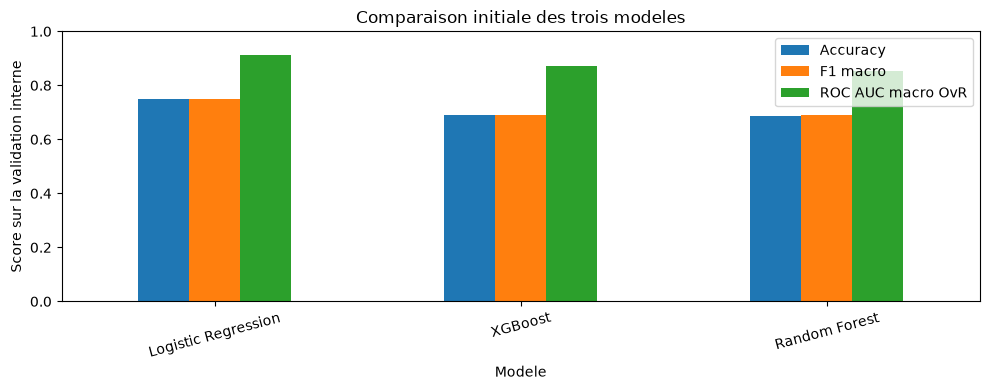

In [7]:
comparison[["Accuracy", "F1 macro", "ROC AUC macro OvR"]].plot(
    kind="bar", figsize=(10, 4), ylim=(0, 1)
)
plt.ylabel("Score sur la validation interne")
plt.title("Comparaison initiale des trois modeles")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()
